# Chapter 8 — Learning Signal and Ignoring Noise: Regularization and Batching

> **Book:** *Grokking Deep Learning* (Andrew W. Trask, Manning)
> **Notebook goal:** summarize Chapter 8, explain every theory, reproduce the code (overfitting, early stopping, dropout, mini-batch gradient descent).

> ⚙️ **Dataset note.** The book uses **MNIST** (28×28 images, downloaded from the web). To keep this notebook fully self-contained/offline we use scikit-learn's bundled **`load_digits`** (8×8 handwritten digits, 1 797 images, 64 pixels). To make overfitting clearly visible on such an easy dataset we (a) train on only **100** images and (b) add Gaussian pixel noise (σ = 0.35). The algorithms are *identical* to the book's; only the data loader differs. To use real MNIST, replace the data cell with `keras.datasets.mnist.load_data()` and set the first-layer size to 784.

---

## 1. Chapter Summary

Chapter 8 introduces the central practical problem of machine learning — **overfitting** — and the tools to fight it.

1. **3-layer network on MNIST/digits.** Input pixels → hidden layer (ReLU) → 10 outputs (one per digit), trained with MSE and gradient descent. It reaches ~100 % accuracy on the training set.
2. **Memorization vs. generalization.** Training accuracy is *not* what we care about. The network could simply *memorize* the training images. We must measure accuracy on **unseen test data**.
3. **Overfitting.** When the network starts modelling *noise* (idiosyncrasies of the specific training examples) instead of *signal* (the real pattern), training accuracy keeps rising while test accuracy stalls or falls. Analogy: a *clay mold* — a network that has seen too few examples makes a mold that fits those few examples perfectly but not new ones.
4. **Where does overfitting come from?** Too many parameters relative to the amount of data, or too little data, or noisy data. A network with enough capacity can fit *anything*, including noise.
5. **Regularization** — any technique that forces the network to ignore noise / prefer simpler solutions:
   * **Early stopping** — stop training when test (validation) error is lowest.
   * **Dropout** — randomly turn off hidden nodes during training.
   * **Batch gradient descent** — average the weight updates over mini-batches.
6. **Dropout** — "training a huge ensemble of small networks": at each step, each hidden node is zeroed with probability 0.5 and the remaining activations are multiplied by 2 to keep the expected signal. *At test time dropout is **off**.*
7. **Batch gradient descent** — update the weights from the *average* gradient over a batch (e.g. 100 images). Averaging cancels noisy, idiosyncratic updates and makes training smoother/faster in wall-clock time (matrix operations).

---

## 2. Theory Deep-Dive

### 2.1 Train / test split and generalization
We always keep a part of the data *out of training*. 
$$\text{generalization} = \text{performance on data the model has never seen}$$

### 2.2 Overfitting – the "signal vs. noise" view
Each example = **signal** (what all images of a "7" share) + **noise** (stroke quirks of that one image). Weights are updated to reduce the error on *each* example, so with enough capacity they start to encode the noise as well. Symptoms:

| Training accuracy | Test accuracy | Meaning |
|---|---|---|
| ↑ to ~100 % | plateaus / drops | **overfitting** |
| low | low | **underfitting** |
| high | high | good generalization |

### 2.3 Early stopping
Because the first thing a network learns is the *broad, shared* signal (it reduces error for the most examples), noise is learned later. Stop training at the best **test/validation** score. Simple, but needs a held-out set *not* used for final reporting (in a real project: train / validation / test).

### 2.4 Dropout
During training for each hidden unit $j$ draw a mask $m_j\sim\text{Bernoulli}(0.5)$:
$$ l_1 \leftarrow (l_1\odot m)\times 2$$
* Multiplying by 2 keeps the expected sum going into the next layer unchanged.
* The back-propagated delta is also masked: $d_1\leftarrow d_1\odot m$ (a unit that was off can't be blamed).
* **Why it works:** it prevents hidden nodes from "co-adapting" — conspiring to memorise a particular training example — because any node may vanish at any time. Each step trains a *different random sub-network*; the full network at test time behaves like an **ensemble** average of them. The surviving nodes must each detect something *genuinely* useful (signal) rather than rely on specific partners.

### 2.5 Mini-batch gradient descent
Three flavours:

| Variant | Update uses | Pros / cons |
|---|---|---|
| Stochastic (batch = 1) | 1 example | noisy, slow in wall-clock |
| **Mini-batch** (e.g. 10-100) | average over the batch | smoother, vectorised → fast (a mild regularizer at best) |
| Full batch | all examples | smooth, 1 update/epoch → slow convergence |

Update with the batch: $\Delta W=\frac1B\,l^T d$ (averaged over $B$ examples). Because `alpha` multiplies an *averaged* gradient, we can use larger `alpha`. Averaging acts as regularization: noise in individual examples tends to cancel while consistent signal adds up.

---

## 3. Code Reproduction

### 3.1 Data

train: (100, 64)  test: (1697, 64)


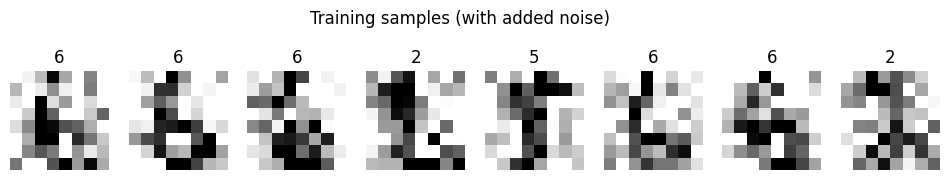

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.datasets import load_digits
os.makedirs("folder-picture", exist_ok=True)

digits = load_digits()
X_all = digits.data / 16.0                       # pixels in [0, 1]
y_all = digits.target

# make the (easy) dataset noisier so that overfitting is clearly visible
noise_rng = np.random.default_rng(5)
X_all = np.clip(X_all + noise_rng.normal(0, 0.35, X_all.shape), 0, 1)

perm = np.random.default_rng(0).permutation(len(X_all))
N_TRAIN = 100
tr, te = perm[:N_TRAIN], perm[N_TRAIN:]
x_train, y_train = X_all[tr], y_all[tr]
x_test,  y_test  = X_all[te], y_all[te]
labels_train = np.eye(10)[y_train]

print("train:", x_train.shape, " test:", x_test.shape)

fig, ax = plt.subplots(1, 8, figsize=(12, 1.9))
for k in range(8):
    ax[k].imshow(x_train[k].reshape(8, 8), cmap="gray_r"); ax[k].set_title(int(y_train[k])); ax[k].axis("off")
plt.suptitle("Training samples (with added noise)", y=1.08)
plt.savefig("folder-picture/ch08_samples.png", dpi=120, bbox_inches="tight")
plt.show()

### 3.2 One configurable training function

`train(...)` implements the 3-layer network `l0 → relu → l1 → l2` with **MSE** loss. Switches: `batch_size` (1 = stochastic), `dropout` (on/off). Each epoch it records train & test accuracy.

In [2]:
relu  = lambda x: (x > 0) * x
relu2 = lambda y: (y > 0) * 1.0

def accuracy(x, y, W0, W1):
    return np.mean((relu(x @ W0) @ W1).argmax(axis=1) == y)

def train(batch_size=1, dropout=False, hidden=200, alpha=0.01, epochs=150, seed=1):
    r = np.random.default_rng(seed)
    W0 = 0.2 * r.random((64, hidden)) - 0.1
    W1 = 0.2 * r.random((hidden, 10)) - 0.1
    tr_acc, te_acc = [], []
    for epoch in range(epochs):
        for s in range(0, N_TRAIN, batch_size):
            l0 = x_train[s:s + batch_size]
            y  = labels_train[s:s + batch_size]
            l1 = relu(l0 @ W0)
            if dropout:
                mask = r.integers(0, 2, size=l1.shape)       # 0 or 1 with prob .5
                l1 = l1 * mask * 2                           # keep expected signal constant
            l2 = l1 @ W1
            d2 = (l2 - y) / len(l0)                          # averaged over the batch
            d1 = (d2 @ W1.T) * relu2(relu(l0 @ W0))
            if dropout:
                d1 = d1 * mask                               # a switched-off node gets no blame
            W1 -= alpha * l1.T @ d2
            W0 -= alpha * l0.T @ d1
        tr_acc.append(accuracy(x_train, y_train, W0, W1))    # NOTE: dropout is OFF when evaluating
        te_acc.append(accuracy(x_test,  y_test,  W0, W1))
    return np.array(tr_acc), np.array(te_acc)

### 3.3 Overfitting: no regularization

In [3]:
tr0, te0 = train(batch_size=1, dropout=False, epochs=150)
print(f"epoch   1: train {tr0[0]:.3f}  test {te0[0]:.3f}")
print(f"epoch  30: train {tr0[29]:.3f}  test {te0[29]:.3f}")
print(f"epoch 150: train {tr0[-1]:.3f}  test {te0[-1]:.3f}")
print("best test accuracy during training:", te0.max().round(3), "at epoch", te0.argmax() + 1)

epoch   1: train 0.420  test 0.243
epoch  30: train 1.000  test 0.652
epoch 150: train 1.000  test 0.636
best test accuracy during training: 0.661 at epoch 20


Training accuracy hits **100 %** while test accuracy is far lower: the network *memorised* the 100 training images (and their noise). That gap is **overfitting**.

### 3.4 Regularization 1 — Early stopping (just look at the test curve)

The best test score occurs early in training; continuing only fits noise. (In practice, pick the epoch with the best *validation* accuracy.)

### 3.5 Regularization 2 — Dropout, and 3.6 Regularization 3 — Mini-batches

We average each configuration over 3 random initialisations to reduce luck.

In [4]:
def avg_runs(seeds=(1, 2, 3), **kw):
    runs = [train(seed=s, **kw) for s in seeds]
    return np.mean([r[0] for r in runs], axis=0), np.mean([r[1] for r in runs], axis=0)

configs = {
    "baseline (batch=1, no dropout)":        dict(batch_size=1,  dropout=False, alpha=0.01, epochs=150),
    "+ dropout (batch=1)":                    dict(batch_size=1,  dropout=True,  alpha=0.01, epochs=150),
    "+ mini-batch 10 + dropout":              dict(batch_size=10, dropout=True,  alpha=0.05, epochs=300),
    "mini-batch 10 only (no dropout)":        dict(batch_size=10, dropout=False, alpha=0.05, epochs=300),
}
results = {name: avg_runs(**cfg) for name, cfg in configs.items()}

print(f"{'configuration':36s} {'train acc':>10s} {'final test':>11s} {'best test':>10s}")
for name, (a, b) in results.items():
    print(f"{name:36s} {a[-1]:10.3f} {b[-1]:11.3f} {b.max():10.3f}")

configuration                         train acc  final test  best test
baseline (batch=1, no dropout)            1.000       0.631      0.653
+ dropout (batch=1)                       1.000       0.679      0.681
+ mini-batch 10 + dropout                 1.000       0.676      0.680
mini-batch 10 only (no dropout)           1.000       0.626      0.654


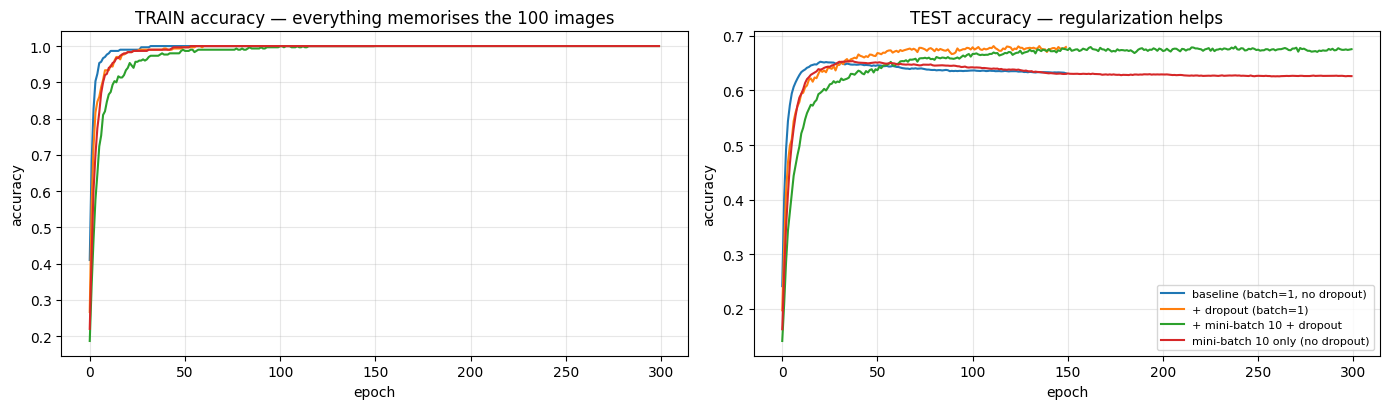

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for name, (a, b) in results.items():
    ax[0].plot(a, label=name)
    ax[1].plot(b, label=name)
ax[0].set_title("TRAIN accuracy — everything memorises the 100 images")
ax[1].set_title("TEST accuracy — regularization helps")
for k in range(2):
    ax[k].set_xlabel("epoch"); ax[k].set_ylabel("accuracy"); ax[k].grid(alpha=.3)
ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("folder-picture/ch08_overfitting_dropout_batching.png", dpi=120, bbox_inches="tight")
plt.show()

**Reading the plot**

* Training accuracy goes to ~100 % for *every* configuration (the network can always memorise 100 examples).
* **Test** accuracy tells the real story: dropout (and mini-batching with dropout) generalises better than the unregularised baseline — the gap between train and test shrinks.
* **Mini-batching alone** (no dropout) did *not* improve test accuracy here (≈ the baseline); on this small dataset its benefit is mainly *speed* (matrix ops over 10 images at once) and smoother updates. The real accuracy gain comes from **dropout**.

> The size of the improvement depends on the dataset; the *direction* is what matters: regularization trades a bit of training fit for better generalization.

---

## 4. Key Takeaways

* Judge a model by its **test** accuracy, never its training accuracy.
* **Overfitting** = learning the noise of the training set; it arises with too much capacity / too little or noisy data.
* **Regularization**: early stopping, **dropout** (random mask ×2 in training, off at test), and **batch** gradient descent (average updates).
* Dropout trains an implicit **ensemble** of sub-networks and stops hidden nodes from co-adapting.
* Mini-batches = averaged gradient → less noisy and faster via vectorisation.

➡️ **Next:** Chapter 9 — modelling **probabilities** with *softmax*, and non-linear **activation functions** (tanh, sigmoid, relu).